In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
from google.colab import files
uploaded = files.upload()   # choose your CSV file

Saving customer_support_tickets (1).csv to customer_support_tickets (1) (1).csv


In [8]:
df = pd.read_csv("customer_support_tickets (1).csv")
# use the exact file name you uploaded
df.head()

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [9]:
df.shape

(8469, 17)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority               8469 non-null   object 
 13  Tic

In [11]:
df.describe()

,Ticket ID,Customer Age,Customer Satisfaction Rating
count,8469.000000,8469.000000,2769.000000
mean,4235.000000,44.026804,2.991333
std,2444.934048,15.296112,1.407016
min,1.000000,18.000000,1.000000
25%,2118.000000,31.000000,2.000000
50%,4235.000000,44.000000,3.000000
75%,6352.000000,57.000000,4.000000
max,8469.000000,70.000000,5.000000


In [12]:
df.describe(include="object")

,Customer Name,Customer Email,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution
count,8469,8469,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769
unique,8028,8320,3,42,730,5,16,8077,3,2769,4,4,5470,2728
top,Michael Garcia,bsmith@example.com,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,We seat culture plan.,Medium,Email,2023-06-01 20:45:39,2023-06-01 17:14:42
freq,5,4,2896,240,24,1752,576,25,2881,1,2192,2143,3,3


In [13]:
df.isnull().sum()

,0
Ticket ID,0
Customer Name,0
Customer Email,0
Customer Age,0
Customer Gender,0
Product Purchased,0
Date of Purchase,0
Ticket Type,0
Ticket Subject,0
Ticket Description,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["Date of Purchase"] = pd.to_datetime(df["Date of Purchase"])
df["First Response Time"] = pd.to_datetime(df["First Response Time"])
df["Time to Resolution"] = pd.to_datetime(df["Time to Resolution"])

In [16]:
df.groupby("Ticket Status")[["Resolution", "Time to Resolution",
                             "Customer Satisfaction Rating", "First Response Time"]].count()

,Resolution,Time to Resolution,Customer Satisfaction Rating,First Response Time
Ticket Status,,,,
Closed,2769,2769,2769,2769
Open,0,0,0,0
Pending Customer Response,0,0,0,2881


In [19]:
df["Ticket Description"] = df.apply(
      lambda r: r["Ticket Description"].replace("{product_purchased}", r["Product Purchased"]),
          axis=1)


In [20]:
df["Resolution Hours"] = (df["Time to Resolution"] - df["First Response Time"]).dt.total_seconds() / 3600
print("Negative (invalid) values:", (df["Resolution Hours"] < 0).sum())

df["Valid Resolution Time"] = df["Resolution Hours"] >= 0
df["Resolution Hours Clean"] = df["Resolution Hours"].where(df["Valid Resolution Time"])

Negative (invalid) values: 1365


In [22]:
df["Age Group"] = pd.cut(df["Customer Age"], bins=[17, 25, 35, 45, 55, 70],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-70"])
df["Purchase Year"] = df["Date of Purchase"].dt.year
df["Response Hour"] = df["First Response Time"].dt.hour
df["Has Rating"] = df["Customer Satisfaction Rating"].notna()

In [23]:
df_clean = df.drop(columns=["Customer Name", "Customer Email"])

(8469, 23)
Ticket Type        0
Ticket Status      0
Ticket Priority    0
Ticket Channel     0
Customer Gender    0
dtype: int64


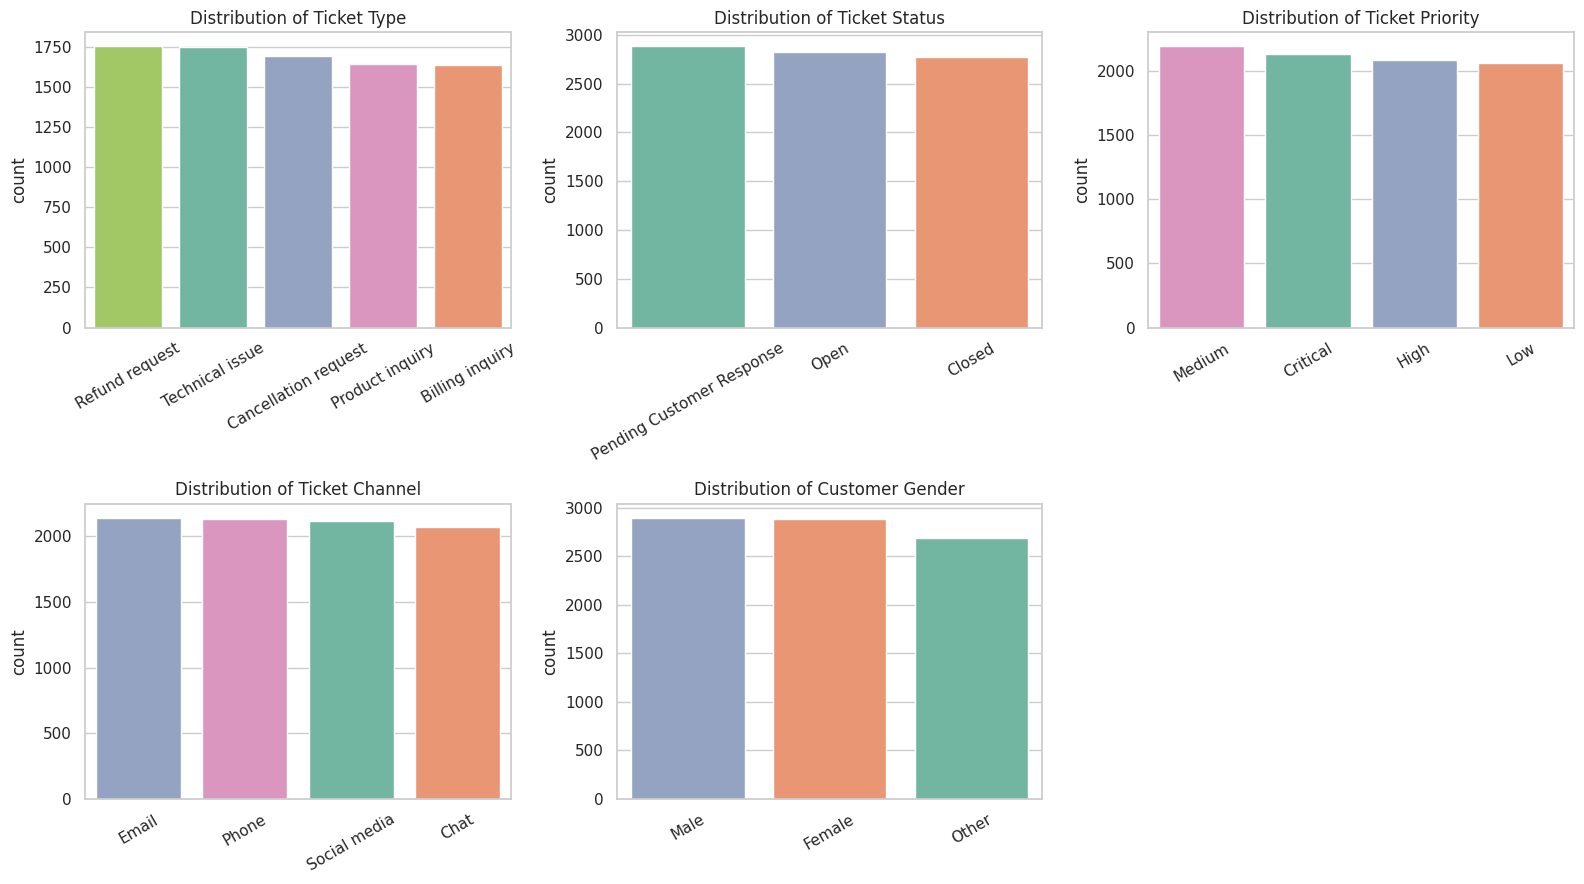

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check the data first (should print 8469 and the right column names)
print(df_clean.shape)
print(df_clean[["Ticket Type", "Ticket Status", "Ticket Priority",
                "Ticket Channel", "Customer Gender"]].isnull().sum())

cols = ["Ticket Type", "Ticket Status", "Ticket Priority", "Ticket Channel", "Customer Gender"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
 # make it a simple list of 6 panels
for ax, c in zip(axes, cols):
    order = df_clean[c].value_counts().index.tolist()
    sns.countplot(data=df_clean, x=c, order=order, hue=c,
    palette="Set2", legend=False, ax=ax)
    ax.set_title(f"Distribution of {c}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)

fig.delaxes(axes[-1])

 # removes the unused 6th panel completely
plt.tight_layout()
plt.show()

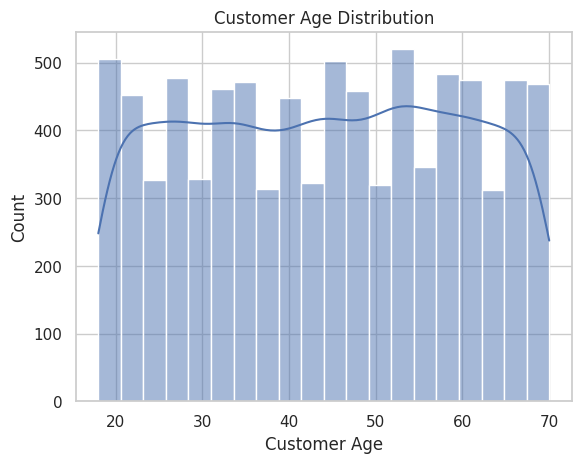

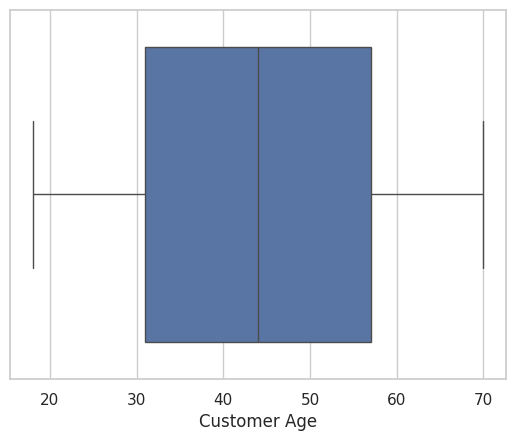

In [26]:
sns.histplot(df_clean["Customer Age"], bins=20, kde=True)
plt.title("Customer Age Distribution"); plt.show()
sns.boxplot(x=df_clean["Customer Age"]); plt.show()

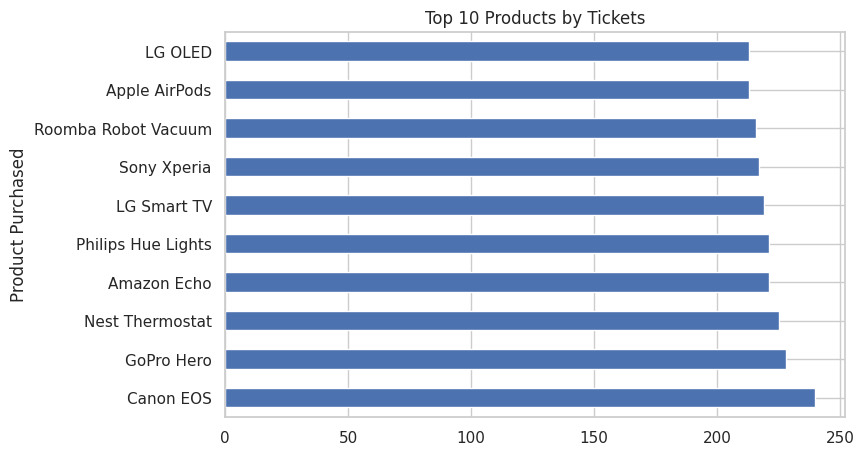

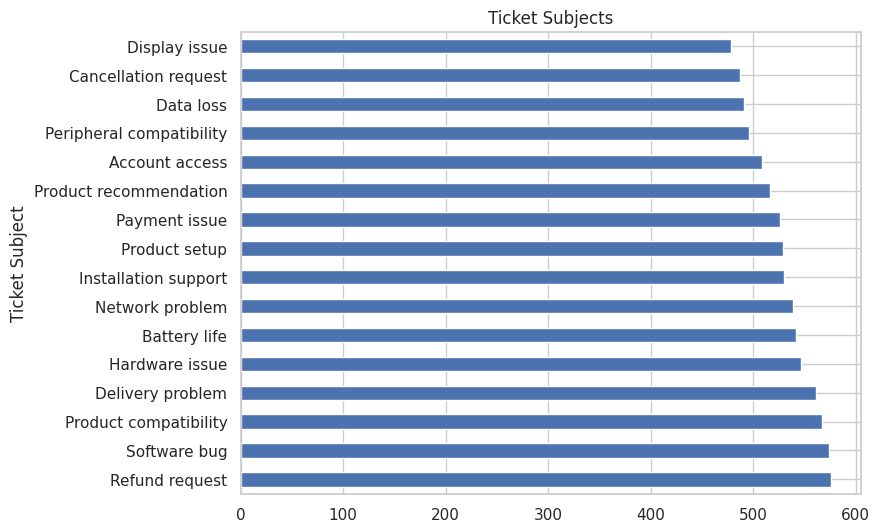

In [27]:
df_clean["Product Purchased"].value_counts().head(10).plot(kind="barh", figsize=(8,5), title="Top 10 Products by Tickets")
plt.show()
df_clean["Ticket Subject"].value_counts().plot(kind="barh", figsize=(8,6), title="Ticket Subjects")
plt.show()

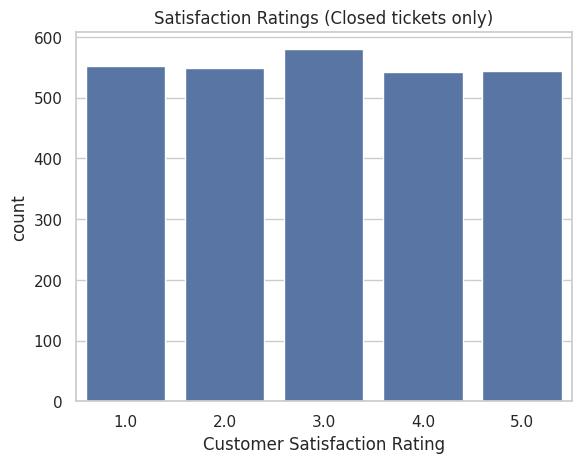

Average rating: 2.991332611050921


In [28]:
sns.countplot(data=df_clean, x="Customer Satisfaction Rating")
plt.title("Satisfaction Ratings (Closed tickets only)"); plt.show()
print("Average rating:", df_clean["Customer Satisfaction Rating"].mean())

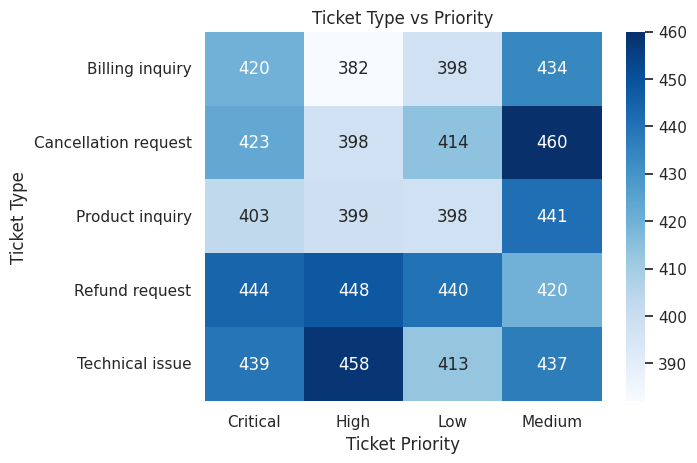

In [29]:
ct = pd.crosstab(df_clean["Ticket Type"], df_clean["Ticket Priority"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues"); plt.title("Ticket Type vs Priority"); plt.show()

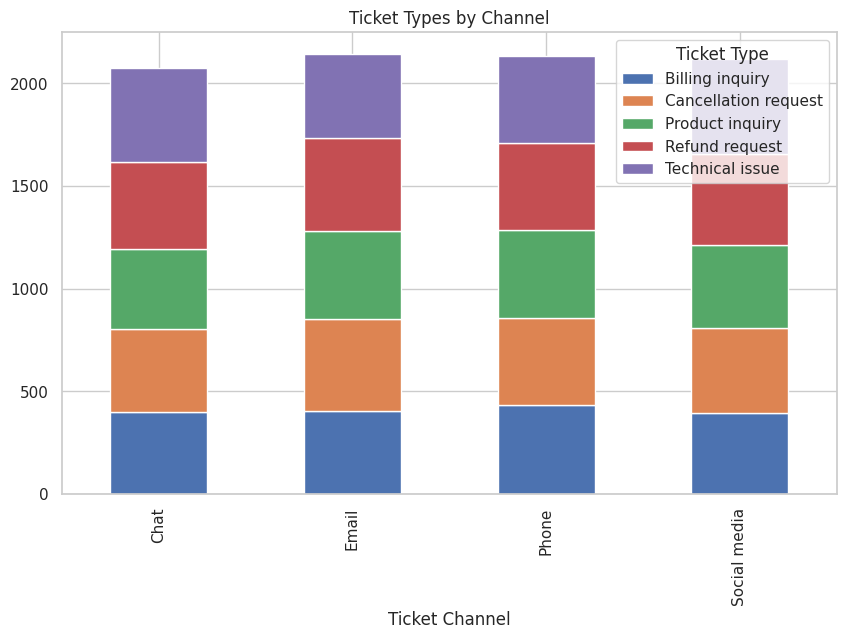

In [30]:
pd.crosstab(df_clean["Ticket Channel"], df_clean["Ticket Type"]).plot(kind="bar", stacked=True, figsize=(10,6))
plt.title("Ticket Types by Channel"); plt.show()

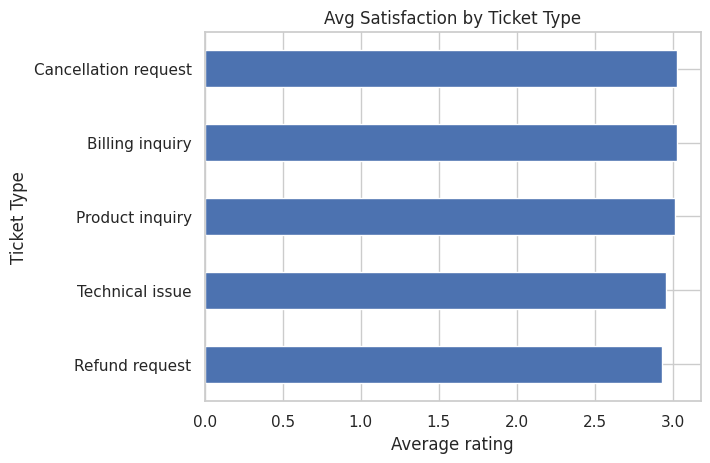

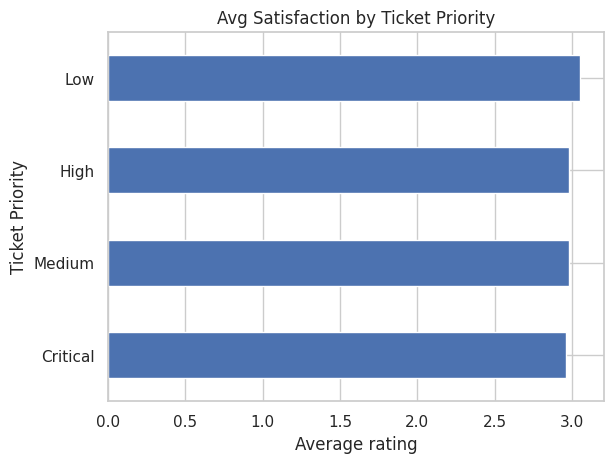

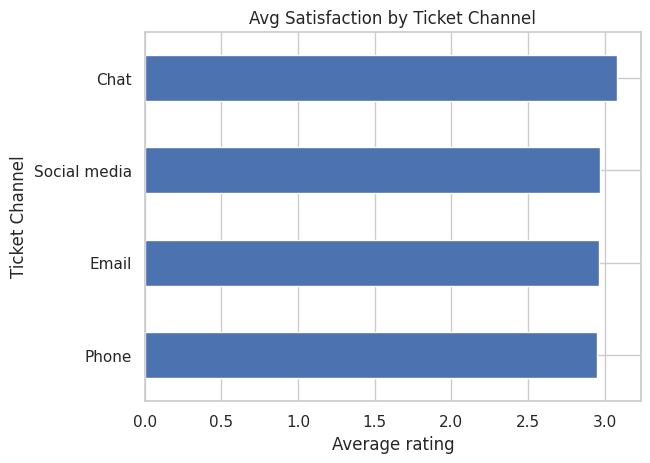

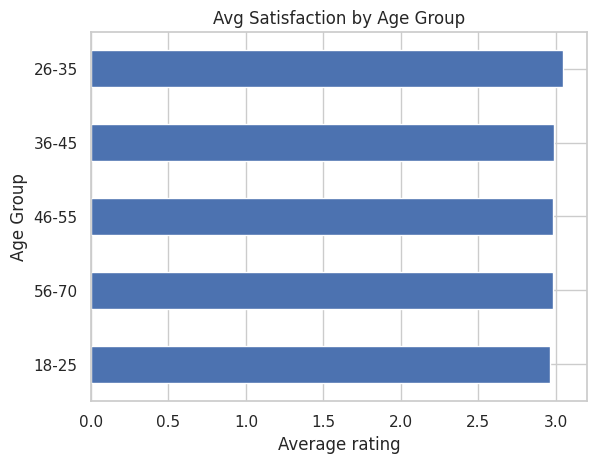

In [32]:
rated = df_clean.dropna(subset=["Customer Satisfaction Rating"])
for c in ["Ticket Type", "Ticket Priority", "Ticket Channel", "Age Group"]:
    rated.groupby(c, observed=True)["Customer Satisfaction Rating"].mean().sort_values().plot(
    kind="barh", title=f"Avg Satisfaction by {c}")
    plt.xlabel("Average rating"); plt.show()

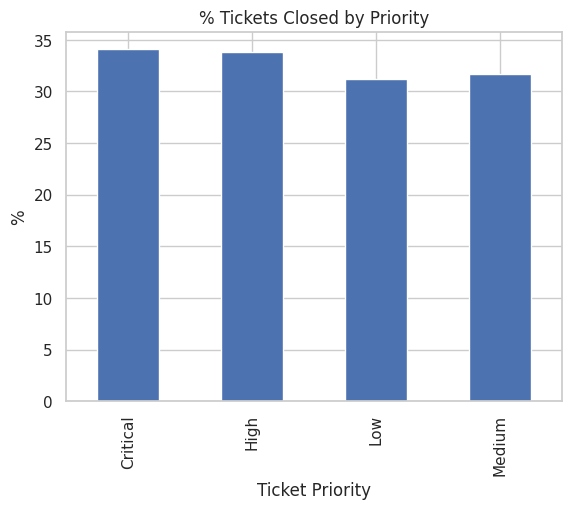

In [33]:
df_clean["Closed"] = (df_clean["Ticket Status"] == "Closed").astype(int)
(df_clean.groupby("Ticket Priority")["Closed"].mean() * 100).plot(kind="bar", title="% Tickets Closed by Priority")
plt.ylabel("%"); plt.show()

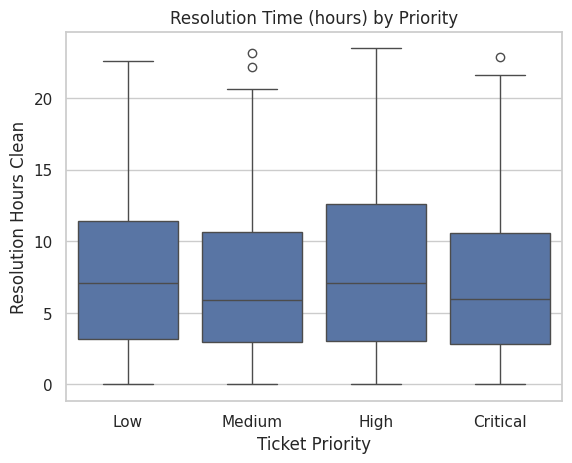

In [35]:
sns.boxplot(data=df_clean, x="Ticket Priority", y="Resolution Hours Clean",
order=["Low", "Medium", "High", "Critical"])
plt.title("Resolution Time (hours) by Priority"); plt.show()

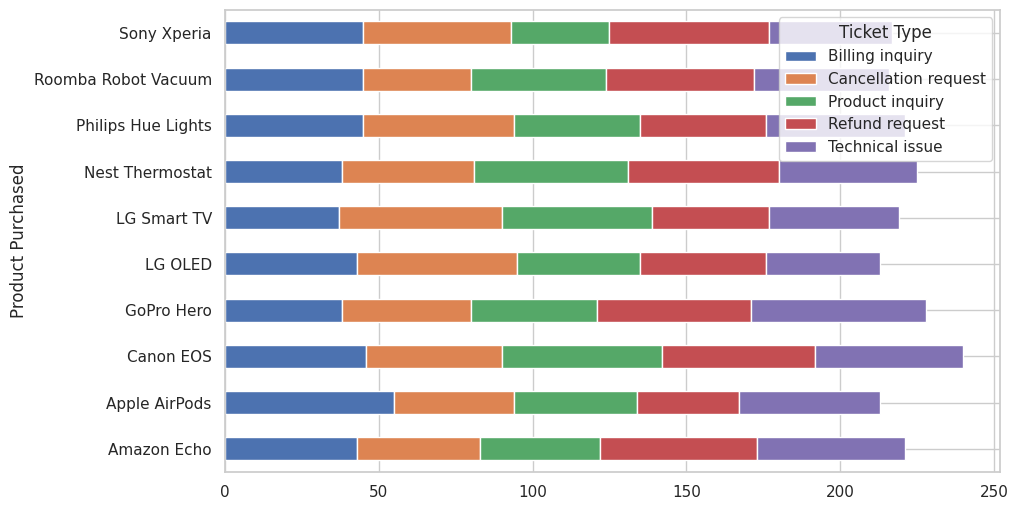

In [36]:
top = df_clean["Product Purchased"].value_counts().head(10).index
pd.crosstab(df_clean[df_clean["Product Purchased"].isin(top)]["Product Purchased"],
df_clean["Ticket Type"]).plot(kind="barh", stacked=True, figsize=(10,6))
plt.show()

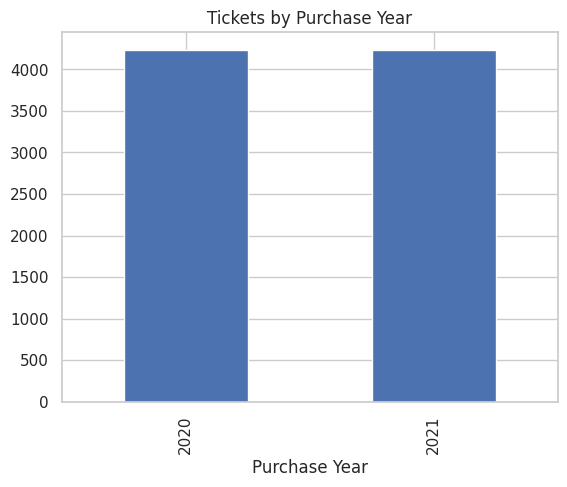

In [37]:
df_clean["Purchase Year"].value_counts().sort_index().plot(kind="bar", title="Tickets by Purchase Year")
plt.show()

In [39]:
from scipy.stats import chi2_contingency
for a, b in [("Ticket Type", "Ticket Channel"), ("Ticket Type", "Ticket Priority"), ("Ticket Priority", "Ticket Status")]:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df_clean[a], df_clean[b]))
    print(f"{a} vs {b}: chi2={chi2:.2f}, p-value={p:.4f}",
    "-> Significant" if p < 0.05 else "-> Not significant")

Ticket Type vs Ticket Channel: chi2=11.85, p-value=0.4578 -> Not significant
Ticket Type vs Ticket Priority: chi2=10.63, p-value=0.5613 -> Not significant
Ticket Priority vs Ticket Status: chi2=8.15, p-value=0.2270 -> Not significant


In [40]:
from scipy.stats import f_oneway
groups = [g["Customer Satisfaction Rating"].values for _, g in rated.groupby("Ticket Type")]
f, p = f_oneway(*groups)
print(f"ANOVA: F={f:.3f}, p={p:.4f}")

ANOVA: F=0.548, p=0.7008


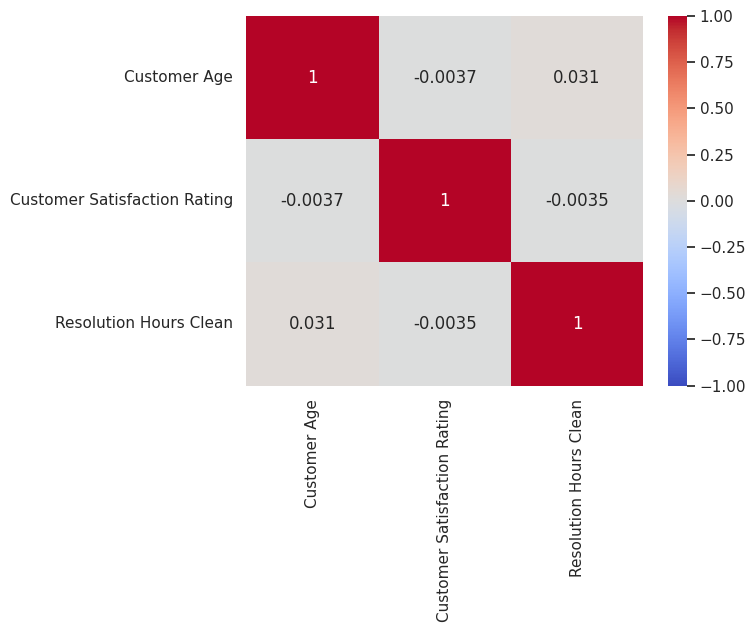

In [41]:
num = df_clean[["Customer Age", "Customer Satisfaction Rating", "Resolution Hours Clean"]]
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1); plt.show()

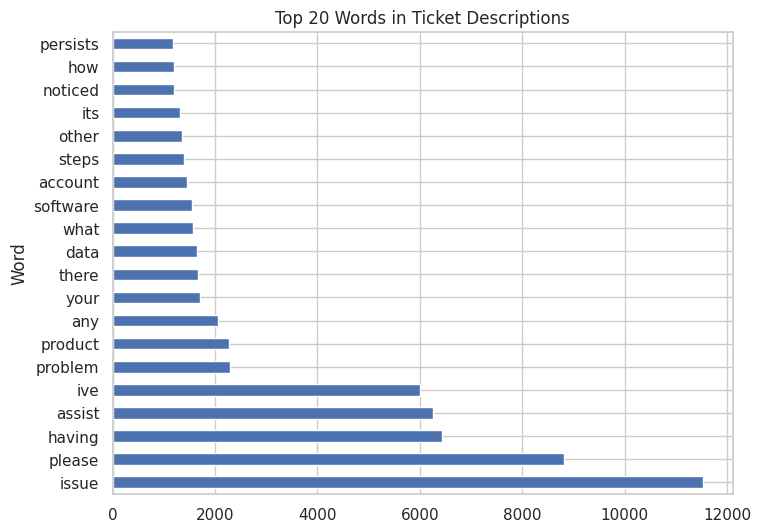

In [42]:
from collections import Counter
import re
words = " ".join(df_clean["Ticket Description"].str.lower()).split()
words = [re.sub(r"[^a-z]", "", w) for w in words]
stop = {"the","i","a","to","and","my","is","with","it","of","in","for","on","this","that","have","but","not","an","me","be","are","can","you","was","or","as","at","if","so","do","when"}
common = Counter(w for w in words if w and w not in stop and len(w) > 2).most_common(20)
pd.DataFrame(common, columns=["Word", "Count"]).set_index("Word").plot(kind="barh", figsize=(8,6), legend=False)
plt.title("Top 20 Words in Ticket Descriptions"); plt.show()

In [46]:
df_clean.to_csv("cleaned_support_tickets.csv", index=False)
files.download("cleaned_support_tickets.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>